<a href="https://colab.research.google.com/github/wani0502/quantum-ml/blob/main/mnist_qnn_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q qiskit qiskit-machine-learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.5 MB/s eta 0:00:00


In [ ]:
import qiskit
import qiskit_machine_learning
import numpy as np
import matplotlib.pyplot as plt

print("Qiskit:", qiskit.__version__)
print("Qiskit Machine Learning:", qiskit_machine_learning.__version__)
print("NumPy:", np.__version__)

Qiskit: 2.6.0
Qiskit Machine Learning: 0.9.1
NumPy: 2.1.3


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile
import os

zip_path = next(
    name for name in uploaded
    if name.endswith(".zip")
)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/mnist")

print(os.listdir("/content/mnist"))

['t10k-images.idx3-ubyte', 'train-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-labels.idx1-ubyte']


In [ ]:
import zipfile
import os

for filename in uploaded:
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall("/content/mnist")

print("Extraction complete")

Extraction complete


In [ ]:
import os

for root, dirs, files in os.walk("/content/mnist"):
    for file in files:
        print(os.path.join(root, file))

/content/mnist/t10k-images.idx3-ubyte
/content/mnist/train-images.idx3-ubyte
/content/mnist/t10k-labels.idx1-ubyte
/content/mnist/train-labels.idx1-ubyte


In [ ]:
import os
import struct
import numpy as np

ROOT = "/content/mnist"

def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        assert magic == 2051, f"Invalid image file: {path}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(n, rows, cols).copy()

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049, f"Invalid label file: {path}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.copy()

X_train = read_idx_images(os.path.join(ROOT, "train-images.idx3-ubyte"))
y_train = read_idx_labels(os.path.join(ROOT, "train-labels.idx1-ubyte"))

X_test = read_idx_images(os.path.join(ROOT, "t10k-images.idx3-ubyte"))
y_test = read_idx_labels(os.path.join(ROOT, "t10k-labels.idx1-ubyte"))

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [ ]:
train_mask = np.isin(y_train, [3, 6])
test_mask = np.isin(y_test, [3, 6])

X_train_36 = X_train[train_mask]
y_train_digits = y_train[train_mask]

X_test_36 = X_test[test_mask]
y_test_digits = y_test[test_mask]

y_train_qnn = np.where(y_train_digits == 3, 1.0, -1.0)
y_test_qnn = np.where(y_test_digits == 3, 1.0, -1.0)

print("Training:", X_train_36.shape)
print("Testing:", X_test_36.shape)
print("Training counts:", {
    3: int(np.sum(y_train_digits == 3)),
    6: int(np.sum(y_train_digits == 6))
})
print("Testing counts:", {
    3: int(np.sum(y_test_digits == 3)),
    6: int(np.sum(y_test_digits == 6))
})

Training: (12049, 28, 28)
Testing: (1968, 28, 28)
Training counts: {3: 6131, 6: 5918}
Testing counts: {3: 1010, 6: 958}


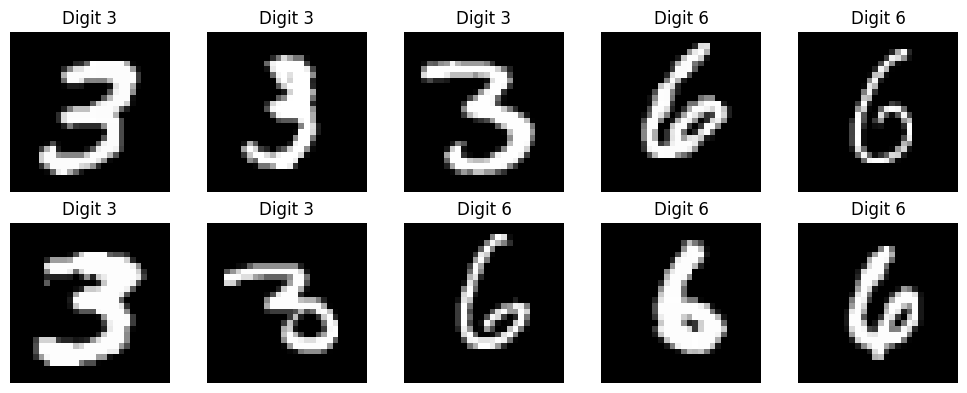

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, img, label in zip(
    axes.flat, X_train_36[:10], y_train_digits[:10]
):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Digit {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def preprocess_images(images):
    resized = []

    for img in images:
        pil_img = Image.fromarray(img)
        pil_img = pil_img.resize((4, 4), Image.Resampling.BILINEAR)
        resized.append(np.array(pil_img, dtype=np.float32) / 255.0)

    resized = np.array(resized)
    binary = (resized >= 0.5).astype(np.int8)

    return resized, binary

X_train_small, X_train_binary = preprocess_images(X_train_36)
X_test_small, X_test_binary = preprocess_images(X_test_36)

print("Resized training:", X_train_small.shape)
print("Binary training:", X_train_binary.shape)
print("Resized testing:", X_test_small.shape)
print("Binary testing:", X_test_binary.shape)

Resized training: (12049, 4, 4)
Binary training: (12049, 4, 4)
Resized testing: (1968, 4, 4)
Binary testing: (1968, 4, 4)


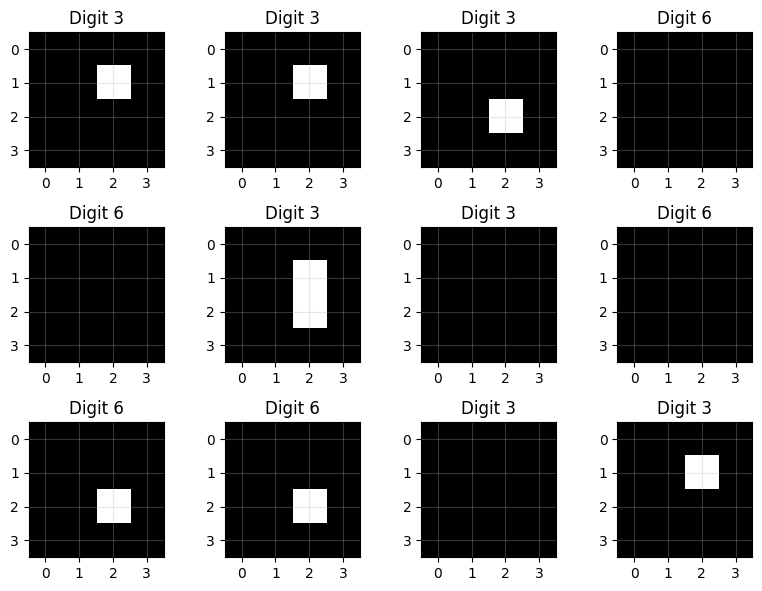

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(8, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_binary[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Digit {y_train_digits[i]}")
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
X_train_bits = X_train_binary.reshape(len(X_train_binary), 16)
X_test_bits = X_test_binary.reshape(len(X_test_binary), 16)

print("Training vectors:", X_train_bits.shape)
print("Testing vectors:", X_test_bits.shape)
print("Example 4x4 image:\n", X_train_binary[0])
print("Example 16-bit vector:\n", X_train_bits[0])

Training vectors: (12049, 16)
Testing vectors: (1968, 16)
Example 4x4 image:
 [[0 0 0 0]
 [0 0 1 0]
 [0 0 0 0]
 [0 0 0 0]]
Example 16-bit vector:
 [0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]


In [ ]:
%pip install -q qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 55.9 MB/s eta 0:00:00


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def image_to_circuit(image_bits):
    qc = QuantumCircuit(16)

    for i, bit in enumerate(image_bits):
        if bit == 1:
            qc.x(i)

    return qc

# Encode one example
example_circuit = image_to_circuit(X_train_bits[0])

print("Number of qubits:", example_circuit.num_qubits)
print(example_circuit.draw(output="text"))

Number of qubits: 16
           
 q_0: ─────
           
 q_1: ─────
           
 q_2: ─────
           
 q_3: ─────
           
 q_4: ─────
           
 q_5: ─────
      ┌───┐
 q_6: ┤ X ├
      └───┘
 q_7: ─────
           
 q_8: ─────
           
 q_9: ─────
           
q_10: ─────
           
q_11: ─────
           
q_12: ─────
           
q_13: ─────
           
q_14: ─────
           
q_15: ─────
           


In [ ]:
def image_to_circuit(image_bits):
    qc = QuantumCircuit(16)

    for i, bit in enumerate(image_bits):
        if bit == 1:
            qc.x(i)

    return qc

example_circuit = image_to_circuit(X_train_bits[0])

test_circuit = example_circuit.copy()
test_circuit.measure_all()

simulator = AerSimulator()
result = simulator.run(test_circuit, shots=100).result()

print("Qubits:", example_circuit.num_qubits)
print("Measurement counts:", result.get_counts())
print(example_circuit.draw(output="text"))

Qubits: 16
Measurement counts: {'0000000001000000': 100}
           
 q_0: ─────
           
 q_1: ─────
           
 q_2: ─────
           
 q_3: ─────
           
 q_4: ─────
           
 q_5: ─────
      ┌───┐
 q_6: ┤ X ├
      └───┘
 q_7: ─────
           
 q_8: ─────
           
 q_9: ─────
           
q_10: ─────
           
q_11: ─────
           
q_12: ─────
           
q_13: ─────
           
q_14: ─────
           
q_15: ─────
           


In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# 16 data qubits + 1 readout qubit
N_DATA = 16
READOUT = 16

# Two trainable layers, each with 16 parameters
xx_params = ParameterVector("xx", N_DATA)
zz_params = ParameterVector("zz", N_DATA)

def build_paper_qnn():
    qc = QuantumCircuit(N_DATA + 1)

    # Readout preparation: X followed by H
    qc.x(READOUT)
    qc.h(READOUT)

    # First layer: parameterized XX interactions
    for i in range(N_DATA):
        qc.rxx(xx_params[i], i, READOUT)

    # Second layer: parameterized ZZ interactions
    for i in range(N_DATA):
        qc.rzz(zz_params[i], i, READOUT)

    # Final readout rotation
    qc.h(READOUT)

    return qc

qnn_circuit = build_paper_qnn()

print("Total qubits:", qnn_circuit.num_qubits)
print("Trainable parameters:", len(qnn_circuit.parameters))
print(qnn_circuit.draw(output="text", fold=100))

Total qubits: 17
Trainable parameters: 32
                ┌─────────────┐                                                            »
 q_0: ──────────┤0            ├────────────────────────────────────────────────────────────»
                │             │┌─────────────┐                                             »
 q_1: ──────────┤             ├┤0            ├─────────────────────────────────────────────»
                │             ││             │┌─────────────┐                              »
 q_2: ──────────┤             ├┤             ├┤0            ├──────────────────────────────»
                │             ││             ││             │┌─────────────┐               »
 q_3: ──────────┤             ├┤             ├┤             ├┤0            ├───────────────»
                │             ││             ││             ││             │┌─────────────┐»
 q_4: ──────────┤             ├┤             ├┤             ├┤             ├┤0            ├»
                │           

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np

def build_image_qnn(image_bits):
    qc = QuantumCircuit(17)

    # Encode the 16 binary pixels
    for i, bit in enumerate(image_bits):
        if bit == 1:
            qc.x(i)

    # Readout preparation
    qc.x(16)
    qc.h(16)

    # Parameterized XX layer
    for i in range(16):
        qc.rxx(xx_params[i], i, 16)

    # Parameterized ZZ layer
    for i in range(16):
        qc.rzz(zz_params[i], i, 16)

    # Readout rotation
    qc.h(16)

    return qc

example_qnn = build_image_qnn(X_train_bits[0])

print("Qubits:", example_qnn.num_qubits)
print("Trainable parameters:", len(example_qnn.parameters))
print("Operations:", example_qnn.count_ops())

Qubits: 17
Trainable parameters: 32
Operations: OrderedDict({'rxx': 16, 'rzz': 16, 'x': 2, 'h': 2})


In [ ]:
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np

zero_params = {
    param: 0.0
    for param in example_qnn.parameters
}

bound_circuit = example_qnn.assign_parameters(zero_params)

# Measure Pauli-Z on readout qubit 16
z_readout = SparsePauliOp("Z" + "I" * 16)

state = Statevector.from_instruction(bound_circuit)

expectation = float(
    np.real(state.expectation_value(z_readout))
)

print("Readout expectation:", expectation)
print("Predicted class:", 3 if expectation >= 0 else 6)

Readout expectation: -0.9999999999999996
Predicted class: 6


In [ ]:
import numpy as np

def remove_contradictions_before_binarizing(images, labels):
    # Use the resized grayscale images, not binary images
    flat = images.reshape(len(images), -1)

    unique_images, inverse = np.unique(
        flat, axis=0, return_inverse=True
    )

    label_counts = np.zeros((len(unique_images), 2), dtype=int)

    for idx, label in zip(inverse, labels):
        label_counts[idx, int(label == 1)] += 1

    contradictory = np.all(label_counts > 0, axis=1)
    keep = ~contradictory[inverse]

    return images[keep], labels[keep]

# Filter resized grayscale images before thresholding
X_train_small_clean, y_train_clean = (
    remove_contradictions_before_binarizing(
        X_train_small, y_train_qnn
    )
)

# Now perform binary encoding
X_train_binary_clean = (
    X_train_small_clean >= 0.5
).astype(np.int8)

X_train_bits_clean = X_train_binary_clean.reshape(
    len(X_train_binary_clean), 16
)

print("Training before filtering:", len(X_train_small))
print("Training after filtering:", len(X_train_small_clean))
print("Binary vectors:", X_train_bits_clean.shape)
print("Labels:", np.unique(y_train_clean, return_counts=True))

Training before filtering: 12049
Training after filtering: 12049
Binary vectors: (12049, 16)
Labels: (array([-1.,  1.]), array([5918, 6131]))


In [ ]:
import numpy as np

def remove_contradictory_images(images, labels):
    """
    Remove binary image patterns that have conflicting labels.
    Identical patterns with the same label are retained.
    """
    flat = images.reshape(len(images), -1)

    unique_images, inverse = np.unique(
        flat, axis=0, return_inverse=True
    )

    label_counts = np.zeros((len(unique_images), 2), dtype=int)

    # Label +1 (digit 3) -> column 1
    # Label -1 (digit 6) -> column 0
    for idx, label in zip(inverse, labels):
        label_counts[idx, int(label == 1)] += 1

    # A pattern is contradictory if it occurs with both labels
    contradictory = np.all(label_counts > 0, axis=1)
    keep = ~contradictory[inverse]

    return images[keep], labels[keep]

X_train_clean, y_train_clean = remove_contradictory_images(
    X_train_binary, y_train_qnn
)

print("Training before removal:", len(X_train_binary))
print("Training after removal:", len(X_train_clean))
print("Removed:", len(X_train_binary) - len(X_train_clean))
print("Test set unchanged:", len(X_test_binary))

Training before removal: 12049
Training after removal: 160
Removed: 11889
Test set unchanged: 1968


In [ ]:
import numpy as np

print("Original resized shape:", X_train_small.shape)
print("Data type:", X_train_small.dtype)
print("Min/max:", X_train_small.min(), X_train_small.max())

# Unique grayscale images
gray_unique = np.unique(
    X_train_small.reshape(len(X_train_small), -1),
    axis=0
)

# Unique binary images
binary_unique = np.unique(
    X_train_binary.reshape(len(X_train_binary), -1),
    axis=0
)

print("Unique grayscale images:", len(gray_unique))
print("Unique binary images:", len(binary_unique))

Original resized shape: (12049, 4, 4)
Data type: float32
Min/max: 0.0 0.94509804
Unique grayscale images: 12049
Unique binary images: 21


In [ ]:
flat = X_train_binary.reshape(len(X_train_binary), -1)

unique_images, inverse = np.unique(
    flat, axis=0, return_inverse=True
)

has_3 = np.zeros(len(unique_images), dtype=bool)
has_6 = np.zeros(len(unique_images), dtype=bool)

for i, label in zip(inverse, y_train_digits):
    if label == 3:
        has_3[i] = True
    else:
        has_6[i] = True

print("Unique binary patterns:", len(unique_images))
print("Patterns containing digit 3:", has_3.sum())
print("Patterns containing digit 6:", has_6.sum())
print("Conflicting patterns:", (has_3 & has_6).sum())
print("Non-conflicting patterns:", (~(has_3 & has_6)).sum())

Unique binary patterns: 21
Patterns containing digit 3: 17
Patterns containing digit 6: 17
Conflicting patterns: 13
Non-conflicting patterns: 8


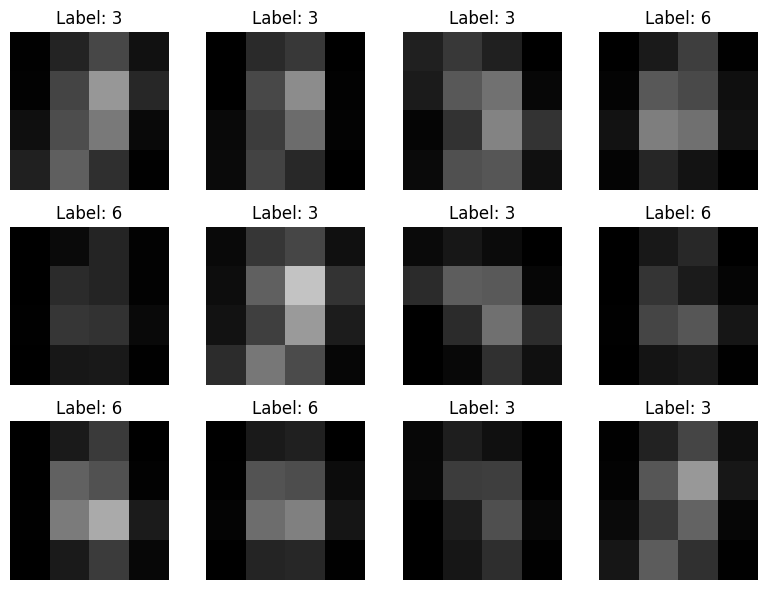

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Display 12 resized grayscale images
fig, axes = plt.subplots(3, 4, figsize=(8, 6))

for ax, i in zip(axes.flat, range(12)):
    ax.imshow(X_train_small[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y_train_digits[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Grayscale unique patterns:",
      len(np.unique(X_train_small.reshape(len(X_train_small), -1), axis=0)))

print("Binary unique patterns:",
      len(np.unique(X_train_binary.reshape(len(X_train_binary), -1), axis=0)))

print("\nFirst grayscale image:")
print(np.round(X_train_small[0], 2))

print("\nIts binary version:")
print(X_train_binary[0].astype(int))

Grayscale unique patterns: 12049
Binary unique patterns: 21

First grayscale image:
[[0.   0.14 0.28 0.07]
 [0.01 0.27 0.59 0.15]
 [0.06 0.3  0.48 0.04]
 [0.13 0.37 0.18 0.  ]]

Its binary version:
[[0 0 0 0]
 [0 0 1 0]
 [0 0 0 0]
 [0 0 0 0]]


In [ ]:
import numpy as np

flat = X_train_small.reshape(len(X_train_small), -1)

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    binary = (flat >= threshold).astype(np.uint8)
    unique_patterns = np.unique(binary, axis=0)

    print(
        f"Threshold={threshold:.1f} | "
        f"Unique patterns={len(unique_patterns)} | "
        f"Average active pixels={binary.sum(axis=1).mean():.2f}/16"
    )

Threshold=0.1 | Unique patterns=441 | Average active pixels=7.98/16
Threshold=0.2 | Unique patterns=325 | Average active pixels=4.91/16
Threshold=0.3 | Unique patterns=134 | Average active pixels=2.70/16
Threshold=0.4 | Unique patterns=51 | Average active pixels=1.38/16
Threshold=0.5 | Unique patterns=21 | Average active pixels=0.56/16


In [ ]:
threshold = 0.1

X_train_binary = (X_train_small >= threshold).astype(np.uint8)
X_test_binary = (X_test_small >= threshold).astype(np.uint8)

print("Training images:", X_train_binary.shape)
print("Test images:", X_test_binary.shape)

print("Unique training patterns:",
      np.unique(X_train_binary.reshape(len(X_train_binary), -1), axis=0).shape[0])

print("Average active pixels:",
      X_train_binary.reshape(len(X_train_binary), -1).sum(axis=1).mean())

Training images: (12049, 4, 4)
Test images: (1968, 4, 4)
Unique training patterns: 441
Average active pixels: 7.976512573657565


In [ ]:
import numpy as np

flat = X_train_binary.reshape(len(X_train_binary), -1)

unique_images, inverse = np.unique(
    flat, axis=0, return_inverse=True
)

has_3 = np.zeros(len(unique_images), dtype=bool)
has_6 = np.zeros(len(unique_images), dtype=bool)

for i, label in zip(inverse, y_train_digits):
    if label == 3:
        has_3[i] = True
    elif label == 6:
        has_6[i] = True

conflicts = has_3 & has_6

print("Unique patterns:", len(unique_images))
print("Patterns containing digit 3:", has_3.sum())
print("Patterns containing digit 6:", has_6.sum())
print("Conflicting patterns:", conflicts.sum())
print("Non-conflicting patterns:", (~conflicts).sum())

Unique patterns: 441
Patterns containing digit 3: 305
Patterns containing digit 6: 220
Conflicting patterns: 84
Non-conflicting patterns: 357


In [ ]:
# Current binary data uses threshold = 0.1
flat = X_train_binary.reshape(len(X_train_binary), -1)

unique_images, inverse, counts = np.unique(
    flat,
    axis=0,
    return_inverse=True,
    return_counts=True
)

has_3 = np.zeros(len(unique_images), dtype=bool)
has_6 = np.zeros(len(unique_images), dtype=bool)

for pattern_id, label in zip(inverse, y_train_digits):
    if label == 3:
        has_3[pattern_id] = True
    else:
        has_6[pattern_id] = True

conflicts = has_3 & has_6
remove_mask = conflicts[inverse]

print("Original training images:", len(y_train_digits))
print("Conflicting patterns:", conflicts.sum())
print("Images in conflicting patterns:", remove_mask.sum())
print("Images remaining:", (~remove_mask).sum())
print("Paper's reported remaining images: 11520")

Original training images: 12049
Conflicting patterns: 84
Images in conflicting patterns: 8969
Images remaining: 3080
Paper's reported remaining images: 11520


In [ ]:
# Restore the complete digit-3-and-digit-6 training set
X_train_36 = X_train[train_mask]
y_train_digits = y_train[train_mask]

y_train_qnn = np.where(y_train_digits == 3, 1.0, -1.0)

print("Training images:", len(y_train_digits))
print("Digit 3:", np.sum(y_train_digits == 3))
print("Digit 6:", np.sum(y_train_digits == 6))

Training images: 12049
Digit 3: 6131
Digit 6: 5918


In [ ]:

import numpy as np

# Use the original 28x28 images for digits 3 and 6
X_original = X_train[train_mask]
y_original = y_train[train_mask]

flat_original = X_original.reshape(len(X_original), -1)

unique_images, inverse, counts = np.unique(
    flat_original,
    axis=0,
    return_inverse=True,
    return_counts=True
)

has_3 = np.zeros(len(unique_images), dtype=bool)
has_6 = np.zeros(len(unique_images), dtype=bool)

for idx, label in zip(inverse, y_original):
    if label == 3:
        has_3[idx] = True
    elif label == 6:
        has_6[idx] = True

conflicts = has_3 & has_6
remove_mask = conflicts[inverse]

print("Original training images:", len(y_original))
print("Unique original images:", len(unique_images))
print("Conflicting patterns:", conflicts.sum())
print("Images in conflicting groups:", remove_mask.sum())
print("Images remaining:", (~remove_mask).sum())
print("Paper's reported remaining images: 11520")

Original training images: 12049
Unique original images: 12049
Conflicting patterns: 0
Images in conflicting groups: 0
Images remaining: 12049
Paper's reported remaining images: 11520


In [ ]:
import numpy as np

flat_gray = X_train_small.reshape(len(X_train_small), -1)

unique_gray, inverse_gray, counts_gray = np.unique(
    flat_gray,
    axis=0,
    return_inverse=True,
    return_counts=True
)

has_3 = np.zeros(len(unique_gray), dtype=bool)
has_6 = np.zeros(len(unique_gray), dtype=bool)

for idx, label in zip(inverse_gray, y_train_digits):
    if label == 3:
        has_3[idx] = True
    else:
        has_6[idx] = True

conflicts_gray = has_3 & has_6
remove_gray = conflicts_gray[inverse_gray]

print("Images before filtering:", len(y_train_digits))
print("Unique resized grayscale images:", len(unique_gray))
print("Conflicting grayscale patterns:", conflicts_gray.sum())
print("Images in conflicting groups:", remove_gray.sum())
print("Images remaining:", (~remove_gray).sum())
print("Paper's reported remaining images: 11520")

Images before filtering: 12049
Unique resized grayscale images: 12049
Conflicting grayscale patterns: 0
Images in conflicting groups: 0
Images remaining: 12049
Paper's reported remaining images: 11520


In [ ]:
import numpy as np

X3 = X_train[y_train == 3]
X6 = X_train[y_train == 6]

# Compare each flattened image across the two classes
flat3 = X3.reshape(len(X3), -1)
flat6 = X6.reshape(len(X6), -1)

images3 = {row.tobytes() for row in flat3}
images6 = {row.tobytes() for row in flat6}

common = images3.intersection(images6)

print("Digit 3 images:", len(images3))
print("Digit 6 images:", len(images6))
print("Exact images shared by both classes:", len(common))
print("Paper's reported training count after filtering: 11520")

Digit 3 images: 6131
Digit 6 images: 5918
Exact images shared by both classes: 0
Paper's reported training count after filtering: 11520


In [ ]:
import sys
import importlib.util

print("Python version:", sys.version)
print("Cirq installed:", importlib.util.find_spec("cirq") is not None)
print("TensorFlow installed:", importlib.util.find_spec("tensorflow") is not None)
print("TensorFlow Quantum installed:",
      importlib.util.find_spec("tensorflow_quantum") is not None)
print("Qiskit installed:", importlib.util.find_spec("qiskit") is not None)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Cirq installed: False
TensorFlow installed: True
TensorFlow Quantum installed: False
Qiskit installed: True


In [ ]:
import qiskit
import qiskit_aer
from qiskit_aer import AerSimulator

print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)

simulator = AerSimulator()
print("Simulator ready:", simulator is not None)

Qiskit: 2.6.0
Aer: 0.18.0
Simulator ready: True


In [ ]:
import numpy as np

THRESHOLD = 0.5

X_train_binary = np.array(
    X_train_small > THRESHOLD,
    dtype=np.float32
)

X_test_binary = np.array(
    X_test_small > THRESHOLD,
    dtype=np.float32
)

# Flatten each 4x4 image into 16 pixel values
X_train_bits = X_train_binary.reshape(len(X_train_binary), 16)
X_test_bits = X_test_binary.reshape(len(X_test_binary), 16)

# Paper's labels: digit 3 = True (+1), digit 6 = False (-1)
y_train_qnn = np.where(y_train_digits == 3, 1.0, -1.0)

print("Training data:", X_train_bits.shape)
print("Training labels:", y_train_qnn.shape)
print("Test data:", X_test_bits.shape)
print("Active pixels in first image:", int(X_train_bits[0].sum()))
print("First image label:", y_train_qnn[0])

Training data: (12049, 16)
Training labels: (12049,)
Test data: (1968, 16)
Active pixels in first image: 1
First image label: 1.0


In [ ]:
from qiskit import QuantumCircuit

def convert_to_circuit(image):
    circuit = QuantumCircuit(16)

    for i, pixel in enumerate(np.asarray(image).flatten()):
        if pixel == 1:
            circuit.x(i)

    return circuit

# Test with one image first
example_circuit = convert_to_circuit(X_train_bits[0])

print("Number of qubits:", example_circuit.num_qubits)
print("Number of X gates:", example_circuit.count_ops().get("x", 0))

example_circuit.draw("mpl")

Number of qubits: 16
Number of X gates: 1


MissingOptionalLibraryError: "The 'pylatexenc' library is required to use 'MatplotlibDrawer'. You can install it with 'pip install pylatexenc'."

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

N_DATA = 16
READOUT = 16

# Trainable parameters for the two gate layers
xx_params = ParameterVector("xx", N_DATA)
zz_params = ParameterVector("zz", N_DATA)

def build_qnn():
    qc = QuantumCircuit(N_DATA + 1)

    # Readout preparation (from the paper)
    qc.x(READOUT)
    qc.h(READOUT)

    # First layer: XX interactions
    for i in range(N_DATA):
        qc.rxx(xx_params[i], i, READOUT)

    # Second layer: ZZ interactions
    for i in range(N_DATA):
        qc.rzz(zz_params[i], i, READOUT)

    # Readout
    qc.h(READOUT)

    return qc

qnn_circuit = build_qnn()

print("Qubits:", qnn_circuit.num_qubits)
print("Trainable parameters:", qnn_circuit.num_parameters)
print("Operations:", qnn_circuit.count_ops())
print(qnn_circuit.draw("text"))

Qubits: 17
Trainable parameters: 32
Operations: OrderedDict({'rxx': 16, 'rzz': 16, 'h': 2, 'x': 1})
                ┌─────────────┐                                             »
 q_0: ──────────┤0            ├─────────────────────────────────────────────»
                │             │┌─────────────┐                              »
 q_1: ──────────┤             ├┤0            ├──────────────────────────────»
                │             ││             │┌─────────────┐               »
 q_2: ──────────┤             ├┤             ├┤0            ├───────────────»
                │             ││             ││             │┌─────────────┐»
 q_3: ──────────┤             ├┤             ├┤             ├┤0            ├»
                │             ││             ││             ││             │»
 q_4: ──────────┤             ├┤             ├┤             ├┤             ├»
                │             ││             ││             ││             │»
 q_5: ──────────┤             ├┤          

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

N_DATA = 16
READOUT = 16

xx_params = ParameterVector("xx", N_DATA)
zz_params = ParameterVector("zz", N_DATA)

def build_image_qnn(image_bits):
    qc = QuantumCircuit(N_DATA + 1)

    # Encode the 4x4 binary image
    for i, pixel in enumerate(image_bits):
        if pixel == 1:
            qc.x(i)

    # Readout preparation
    qc.x(READOUT)
    qc.h(READOUT)

    # Trainable gate layers
    for i in range(N_DATA):
        qc.rxx(xx_params[i], i, READOUT)

    for i in range(N_DATA):
        qc.rzz(zz_params[i], i, READOUT)

    # Readout basis rotation
    qc.h(READOUT)

    return qc

example_qnn = build_image_qnn(X_train_bits[0])

print("Qubits:", example_qnn.num_qubits)
print("Trainable parameters:", example_qnn.num_parameters)
print("Operations:", example_qnn.count_ops())

Qubits: 17
Trainable parameters: 32
Operations: OrderedDict({'rxx': 16, 'rzz': 16, 'x': 2, 'h': 2})


In [ ]:
from qiskit.quantum_info import Statevector, SparsePauliOp

zero_params = {
    param: 0.0 for param in example_qnn.parameters
}

bound_circuit = example_qnn.assign_parameters(zero_params)

# Measure Pauli Z on qubit 16
z_readout = SparsePauliOp("I" * 16 + "Z")

state = Statevector.from_instruction(bound_circuit)

expectation = float(
    np.real(state.expectation_value(z_readout))
)

print("Readout expectation:", round(expectation, 6))
print("Expected range: [-1, 1]")

Readout expectation: 1.0
Expected range: [-1, 1]


In [ ]:
def hinge_loss(y_true, y_pred):
    return np.mean(np.maximum(0, 1 - y_true * y_pred))

# Simple sanity check
y_example = np.array([1.0, -1.0])
pred_example = np.array([0.8, -0.6])

print("Example hinge loss:", hinge_loss(y_example, pred_example))

Example hinge loss: 0.3


In [ ]:
import importlib.util

print(
    "Qiskit Machine Learning installed:",
    importlib.util.find_spec("qiskit_machine_learning") is not None
)
print(
    "SciPy installed:",
    importlib.util.find_spec("scipy") is not None
)

Qiskit Machine Learning installed: True
SciPy installed: True


In [ ]:
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
from qiskit_machine_learning.optimizers import COBYLA

print("SamplerQNN: available")
print("EstimatorQNN: available")
print("COBYLA: available")

SamplerQNN: available
EstimatorQNN: available
COBYLA: available


In [ ]:
import numpy as np

from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.gradients import ParamShiftEstimatorGradient

# Readout observable: Z on qubit 16
observable = SparsePauliOp("I" * 16 + "Z")

# Input parameters are not needed here because image pixels
# are encoded directly with X gates in build_image_qnn().
qnn = EstimatorQNN(
    circuit=qnn_circuit,
    observables=observable,
    input_params=[],
    weight_params=list(qnn_circuit.parameters),
    input_gradients=False
)

print("QNN created successfully")
print("Input shape:", qnn.num_inputs)
print("Trainable weights:", qnn.num_weights)

QNN created successfully
Input shape: 0
Trainable weights: 32


In [ ]:
print("QNN input parameters:", qnn.num_inputs)
print("QNN trainable weights:", qnn.num_weights)

print("\nCircuit parameters:")
for param in qnn_circuit.parameters:
    print(param)

QNN input parameters: 0
QNN trainable weights: 32

Circuit parameters:
xx[0]
xx[1]
xx[2]
xx[3]
xx[4]
xx[5]
xx[6]
xx[7]
xx[8]
xx[9]
xx[10]
xx[11]
xx[12]
xx[13]
xx[14]
xx[15]
zz[0]
zz[1]
zz[2]
zz[3]
zz[4]
zz[5]
zz[6]
zz[7]
zz[8]
zz[9]
zz[10]
zz[11]
zz[12]
zz[13]
zz[14]
zz[15]


In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

N_DATA = 16
READOUT = 16

xx_params = ParameterVector("xx", N_DATA)
zz_params = ParameterVector("zz", N_DATA)

def build_image_qnn(image_bits):
    qc = QuantumCircuit(17)

    # 1. Encode binary pixels using X gates
    for i, pixel in enumerate(image_bits):
        if pixel == 1:
            qc.x(i)

    # 2. Prepare readout qubit
    qc.x(READOUT)
    qc.h(READOUT)

    # 3. Parameterized XX layer
    for i in range(N_DATA):
        qc.rxx(np.pi * xx_params[i], i, READOUT)

    # 4. Parameterized ZZ layer
    for i in range(N_DATA):
        qc.rzz(np.pi * zz_params[i], i, READOUT)

    # 5. Readout
    qc.h(READOUT)

    return qc

# Z observable on readout qubit 16
observable = SparsePauliOp("I" * 16 + "Z")

def predict_one_image(image_bits, weights):
    circuit = build_image_qnn(image_bits)

    bindings = {}
    for i in range(N_DATA):
        bindings[xx_params[i]] = weights[i]
        bindings[zz_params[i]] = weights[N_DATA + i]

    bound = circuit.assign_parameters(bindings)
    state = Statevector.from_instruction(bound)

    return float(np.real(state.expectation_value(observable)))

# Test with 32 shared weights initialized to zero
initial_weights = np.zeros(32, dtype=float)

prediction = predict_one_image(
    X_train_bits[0],
    initial_weights
)

print("Readout prediction:", prediction)
print("Valid output range:", -1.0 <= prediction <= 1.0)
print("Trainable weights:", len(initial_weights))
print("True label:", y_train_qnn[0])

Readout prediction: 0.9999999999999996
Valid output range: True
Trainable weights: 32
True label: 1.0


In [ ]:
import numpy as np
from scipy.optimize import minimize

# Small balanced subset: 16 images from each class
rng = np.random.default_rng(42)

idx3 = np.where(y_train_qnn == 1.0)[0]
idx6 = np.where(y_train_qnn == -1.0)[0]

subset_idx = np.concatenate([
    rng.choice(idx3, size=16, replace=False),
    rng.choice(idx6, size=16, replace=False)
])
rng.shuffle(subset_idx)

X_small = X_train_bits[subset_idx]
y_small = y_train_qnn[subset_idx]

def objective(weights):
    predictions = np.array([
        predict_one_image(image, weights)
        for image in X_small
    ])

    loss = np.mean(np.maximum(0.0, 1.0 - y_small * predictions))
    return loss

initial_weights = rng.uniform(-0.1, 0.1, size=32)

print("Subset size:", len(y_small))
print("Digit 3:", np.sum(y_small == 1.0))
print("Digit 6:", np.sum(y_small == -1.0))
print("Initial hinge loss:", objective(initial_weights))

Subset size: 32
Digit 3: 16
Digit 6: 16
Initial hinge loss: 0.9999999999999996


In [ ]:
rng = np.random.default_rng(42)
test_weights = rng.uniform(-0.5, 0.5, size=32)

predictions = np.array([
    predict_one_image(image, test_weights)
    for image in X_small
])

print("Prediction min:", predictions.min())
print("Prediction max:", predictions.max())
print("Prediction std:", predictions.std())
print("First 8 predictions:", np.round(predictions[:8], 4))
print("Unique binary images in subset:",
      np.unique(X_small, axis=0).shape[0])

Prediction min: 0.6519384318297186
Prediction max: 0.6519384318297315
Prediction std: 3.4120171933669915e-15
First 8 predictions: [0.6519 0.6519 0.6519 0.6519 0.6519 0.6519 0.6519 0.6519]
Unique binary images in subset: 7


In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator

t = 0.25

# Qiskit rotation with angle pi*t
qc = QuantumCircuit(2)
qc.rxx(np.pi * t, 0, 1)

print("Qiskit RXX angle:", np.pi * t)
print("Unitary:")
print(np.round(Operator(qc).data, 4))

Qiskit RXX angle: 0.7853981633974483
Unitary:
[[0.9239+0.j     0.    +0.j     0.    +0.j     0.    -0.3827j]
 [0.    +0.j     0.9239+0.j     0.    -0.3827j 0.    +0.j    ]
 [0.    +0.j     0.    -0.3827j 0.9239+0.j     0.    +0.j    ]
 [0.    -0.3827j 0.    +0.j     0.    +0.j     0.9239+0.j    ]]


In [ ]:
qc = QuantumCircuit(2)
qc.rzz(np.pi * t, 0, 1)

print("Qiskit RZZ angle:", np.pi * t)
print("Unitary:")
print(np.round(Operator(qc).data, 4))

Qiskit RZZ angle: 0.7853981633974483
Unitary:
[[0.9239-0.3827j 0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.9239+0.3827j 0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.9239+0.3827j 0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.9239-0.3827j]]


In [ ]:
rng = np.random.default_rng(42)
test_weights = rng.uniform(-0.5, 0.5, size=32)

# Pick one image from each class
idx3 = np.where(y_train_qnn == 1.0)[0][0]
idx6 = np.where(y_train_qnn == -1.0)[0][0]

pred3 = predict_one_image(X_train_bits[idx3], test_weights)
pred6 = predict_one_image(X_train_bits[idx6], test_weights)

print("Digit 3 prediction:", pred3)
print("Digit 6 prediction:", pred6)
print("Absolute difference:", abs(pred3 - pred6))

Digit 3 prediction: 0.6519384318297287
Digit 6 prediction: 0.6519384318297275
Absolute difference: 1.1102230246251565e-15


In [ ]:
# Check whether different images produce different circuits
qc3 = build_image_qnn(X_train_bits[idx3])
qc6 = build_image_qnn(X_train_bits[idx6])

print("Digit 3 X gates:",
      qc3.count_ops().get("x", 0) - 1)

print("Digit 6 X gates:",
      qc6.count_ops().get("x", 0) - 1)

print("Image encodings identical:",
      np.array_equal(X_train_bits[idx3], X_train_bits[idx6]))

print("Digit 3 active pixels:", int(X_train_bits[idx3].sum()))
print("Digit 6 active pixels:", int(X_train_bits[idx6].sum()))

Digit 3 X gates: 1
Digit 6 X gates: 0
Image encodings identical: False
Digit 3 active pixels: 1
Digit 6 active pixels: 0


In [ ]:
def build_diagnostic_circuit(image_bits, weights, use_xx=True, use_zz=True):
    qc = QuantumCircuit(17)

    for i, pixel in enumerate(image_bits):
        if pixel == 1:
            qc.x(i)

    qc.x(16)
    qc.h(16)

    if use_xx:
        for i in range(16):
            qc.rxx(np.pi * weights[i], i, 16)

    if use_zz:
        for i in range(16):
            qc.rzz(np.pi * weights[16 + i], i, 16)

    qc.h(16)
    return qc

def diagnostic_prediction(image_bits, weights, use_xx=True, use_zz=True):
    qc = build_diagnostic_circuit(image_bits, weights, use_xx, use_zz)
    state = Statevector.from_instruction(qc)
    return float(np.real(state.expectation_value(observable)))

for name, xx, zz in [
    ("XX only", True, False),
    ("ZZ only", False, True),
    ("XX + ZZ", True, True),
]:
    p3 = diagnostic_prediction(X_train_bits[idx3], test_weights, xx, zz)
    p6 = diagnostic_prediction(X_train_bits[idx6], test_weights, xx, zz)
    print(f"{name}: digit 3={p3:.8f}, digit 6={p6:.8f}, difference={abs(p3-p6):.3e}")

XX only: digit 3=0.65193843, digit 6=0.65193843, difference=1.110e-16
ZZ only: digit 3=1.00000000, digit 6=1.00000000, difference=1.110e-16
XX + ZZ: digit 3=0.65193843, digit 6=0.65193843, difference=1.110e-15


In [ ]:
SparsePauliOp("I"*16 + "Z")

SparsePauliOp(['IIIIIIIIIIIIIIIIZ'],
              coeffs=[1.+0.j])

In [ ]:
from qiskit.quantum_info import SparsePauliOp

# Measure Z on readout qubit 16
observable = SparsePauliOp("Z" + "I"*16)

print("Observable:", observable)

Observable: SparsePauliOp(['ZIIIIIIIIIIIIIIII'],
              coeffs=[1.+0.j])


In [ ]:
for name, xx, zz in [
    ("XX only", True, False),
    ("ZZ only", False, True),
    ("XX + ZZ", True, True),
]:
    p3 = diagnostic_prediction(X_train_bits[idx3], test_weights, xx, zz)
    p6 = diagnostic_prediction(X_train_bits[idx6], test_weights, xx, zz)

    print(
        f"{name}: digit 3={p3:.8f}, digit 6={p6:.8f}, "
        f"difference={abs(p3-p6):.3e}"
    )

XX only: digit 3=-1.00000000, digit 6=-1.00000000, difference=0.000e+00
ZZ only: digit 3=-0.89679159, digit 6=0.96263600, difference=1.859e+00
XX + ZZ: digit 3=-0.01491142, digit 6=0.01178842, difference=2.670e-02


In [ ]:
# Use the same test_weights and corrected observable.
# Check several examples from each class.

idx3_list = np.where(y_train_qnn == 1.0)[0][:5]
idx6_list = np.where(y_train_qnn == -1.0)[0][:5]

for name, xx, zz in [
    ("XX only", True, False),
    ("ZZ only", False, True),
    ("XX + ZZ", True, True),
]:
    print(f"\n{name}")

    for idx in list(idx3_list) + list(idx6_list):
        pred = diagnostic_prediction(
            X_train_bits[idx], test_weights, xx, zz
        )
        digit = y_train_digits[idx]
        print(f"Digit {digit}: prediction = {pred:.6f}")


XX only
Digit 3: prediction = -1.000000
Digit 3: prediction = -1.000000
Digit 3: prediction = -1.000000
Digit 3: prediction = -1.000000
Digit 3: prediction = -1.000000
Digit 6: prediction = -1.000000
Digit 6: prediction = -1.000000
Digit 6: prediction = -1.000000
Digit 6: prediction = -1.000000
Digit 6: prediction = -1.000000

ZZ only
Digit 3: prediction = -0.896792
Digit 3: prediction = -0.896792
Digit 3: prediction = 0.885457
Digit 3: prediction = -0.785415
Digit 3: prediction = 0.962636
Digit 6: prediction = 0.962636
Digit 6: prediction = 0.962636
Digit 6: prediction = 0.962636
Digit 6: prediction = 0.885457
Digit 6: prediction = 0.885457

XX + ZZ
Digit 3: prediction = -0.014911
Digit 3: prediction = -0.014911
Digit 3: prediction = 0.014120
Digit 3: prediction = -0.016495
Digit 3: prediction = 0.011788
Digit 6: prediction = 0.011788
Digit 6: prediction = 0.011788
Digit 6: prediction = 0.011788
Digit 6: prediction = 0.014120
Digit 6: prediction = 0.014120


In [ ]:
print("Training images:", X_train_bits.shape)
print("Test images:", X_test_bits.shape)

print("Unique training labels:", np.unique(y_train_qnn))
print("Trainable parameters:", len(test_weights))

print("Digit 3 label:", np.unique(y_train_qnn[y_train_digits == 3]))
print("Digit 6 label:", np.unique(y_train_qnn[y_train_digits == 6]))

def hinge_loss(y_true, y_pred):
    return np.mean(np.maximum(0.0, 1.0 - y_true * y_pred))

print("Sanity-check hinge loss:",
      hinge_loss(
          np.array([1.0, -1.0]),
          np.array([0.7, -0.7])
      ))

Training images: (12049, 16)
Test images: (1968, 16)
Unique training labels: [-1.  1.]
Trainable parameters: 32
Digit 3 label: [1.]
Digit 6 label: [-1.]
Sanity-check hinge loss: 0.30000000000000004


In [ ]:
import scipy
from scipy.optimize import minimize

print("SciPy version:", scipy.__version__)
print("Optimizer available:", minimize is not None)

SciPy version: 1.16.3
Optimizer available: True


In [ ]:

import numpy as np
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector

def predict_one_image(image_bits, weights):
    qc = build_image_qnn(image_bits)

    bindings = {}
    for i in range(16):
        bindings[xx_params[i]] = weights[i]
        bindings[zz_params[i]] = weights[16 + i]

    bound_qc = qc.assign_parameters(bindings)
    state = Statevector.from_instruction(bound_qc)

    return float(np.real(state.expectation_value(observable)))


def hinge_loss(y_true, y_pred):
    return np.mean(np.maximum(0.0, 1.0 - y_true * y_pred))


def objective(weights, X, y):
    predictions = np.array([
        predict_one_image(image, weights)
        for image in X
    ])
    return hinge_loss(y, predictions)


# Reproducible initial parameters
rng = np.random.default_rng(42)
initial_weights = rng.uniform(-0.1, 0.1, size=32)

initial_loss = objective(initial_weights, X_small, y_small)
print("Initial loss:", initial_loss)

result = minimize(
    objective,
    initial_weights,
    args=(X_small, y_small),
    method="COBYLA",
    options={"maxiter": 30, "rhobeg": 0.1}
)

print("Final loss:", result.fun)
print("Optimizer success:", result.success)
print("Optimizer message:", result.message)
print("Iterations/evaluations:", result.nfev)

trained_weights = result.x


Initial loss: 1.0820004686294258


/usr/local/lib/python3.13/dist-packages/scipy/_lib/pyprima/common/preproc.py:68: UserWarning: COBYLA: Invalid MAXFUN; it should be at least num_vars + 2; it is set to 34
  warn(f'{solver}: Invalid MAXFUN; it should be at least {min_maxfun_str}; it is set to {maxfun}')


Final loss: 0.9985451608701901
Optimizer success: False
Optimizer message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
Iterations/evaluations: 34


In [ ]:

import numpy as np

def filter_duplicate_patterns(X, y):
    """
    Keep the first occurrence of each binary pattern within each class.
    Never remove an example just because it matches a pattern in the other class.
    """
    keep_indices = []

    for label in np.unique(y):
        class_indices = np.where(y == label)[0]
        seen = set()

        for idx in class_indices:
            pattern = X[idx].tobytes()

            if pattern not in seen:
                seen.add(pattern)
                keep_indices.append(idx)

    keep_indices = np.array(sorted(keep_indices))

    return X[keep_indices], y[keep_indices], keep_indices


X_train_filtered, y_train_filtered, kept_indices = (
    filter_duplicate_patterns(X_train_bits, y_train_qnn)
)

print("Before filtering:", X_train_bits.shape[0])
print("After filtering:", X_train_filtered.shape[0])
print("Removed:", X_train_bits.shape[0] - len(kept_indices))
print("Digit 3:", np.sum(y_train_filtered == 1))
print("Digit 6:", np.sum(y_train_filtered == -1))

# Count binary patterns that occur in both classes.
patterns_3 = {
    X_train_filtered[i].tobytes()
    for i in range(len(y_train_filtered))
    if y_train_filtered[i] == 1
}
patterns_6 = {
    X_train_filtered[i].tobytes()
    for i in range(len(y_train_filtered))
    if y_train_filtered[i] == -1
}

print("Cross-class pattern collisions:", len(patterns_3 & patterns_6))


Before filtering: 12049
After filtering: 34
Removed: 12015
Digit 3: 17
Digit 6: 17
Cross-class pattern collisions: 13


In [ ]:

import numpy as np

# Stratified train-validation split using NumPy only
rng = np.random.default_rng(42)

train_indices = []
val_indices = []

for label in np.unique(y_train_filtered):
    indices = np.where(y_train_filtered == label)[0]
    rng.shuffle(indices)

    split_point = int(0.8 * len(indices))
    train_indices.extend(indices[:split_point])
    val_indices.extend(indices[split_point:])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)

rng.shuffle(train_indices)
rng.shuffle(val_indices)

X_dev_train = X_train_filtered[train_indices]
y_dev_train = y_train_filtered[train_indices]

X_dev_val = X_train_filtered[val_indices]
y_dev_val = y_train_filtered[val_indices]

# Small balanced subsets for initial circuit training
def balanced_subset(X, y, per_class, seed=42):
    rng = np.random.default_rng(seed)
    selected = []

    for label in [-1.0, 1.0]:
        indices = np.where(y == label)[0]
        count = min(per_class, len(indices))
        selected.extend(
            rng.choice(indices, size=count, replace=False)
        )

    selected = np.array(selected)
    rng.shuffle(selected)

    return X[selected], y[selected]

X_small, y_small = balanced_subset(
    X_dev_train, y_dev_train, per_class=16, seed=42
)

X_val_small, y_val_small = balanced_subset(
    X_dev_val, y_dev_val, per_class=8, seed=43
)

print("Training split:", X_dev_train.shape)
print("Validation split:", X_dev_val.shape)
print("Training subset:", X_small.shape)
print("Validation subset:", X_val_small.shape)
print("Training class counts:", np.unique(y_small, return_counts=True))
print("Validation class counts:", np.unique(y_val_small, return_counts=True))


Training split: (26, 16)
Validation split: (8, 16)
Training subset: (26, 16)
Validation subset: (8, 16)
Training class counts: (array([-1.,  1.]), array([13, 13]))
Validation class counts: (array([-1.,  1.]), array([4, 4]))


In [ ]:

from scipy.optimize import minimize
import numpy as np

def objective(weights, X, y):
    predictions = np.array([
        predict_one_image(image, weights)
        for image in X
    ])
    return hinge_loss(y, predictions)

rng = np.random.default_rng(42)
initial_weights = rng.uniform(-0.1, 0.1, size=32)

initial_loss = objective(initial_weights, X_small, y_small)
print("Initial training loss:", initial_loss)

result = minimize(
    objective,
    initial_weights,
    args=(X_small, y_small),
    method="COBYLA",
    options={
        "maxiter": 60,
        "rhobeg": 0.1,
        "tol": 1e-4
    }
)

trained_weights = result.x

train_predictions = np.array([
    predict_one_image(image, trained_weights)
    for image in X_small
])

val_predictions = np.array([
    predict_one_image(image, trained_weights)
    for image in X_val_small
])

print("Final training loss:", hinge_loss(y_small, train_predictions))
print("Validation loss:", hinge_loss(y_val_small, val_predictions))
print("Optimizer message:", result.message)
print("Function evaluations:", result.nfev)


Initial training loss: 1.0922644977286813
Final training loss: 0.8393505503709231
Validation loss: 0.8924578333575007
Optimizer message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
Function evaluations: 60


In [ ]:

import numpy as np

# Convert model outputs into predicted labels using threshold 0
train_classes = np.where(train_predictions >= 0, 1.0, -1.0)
val_classes = np.where(val_predictions >= 0, 1.0, -1.0)

def evaluate_model(y_true, y_pred, name):
    accuracy = np.mean(y_true == y_pred)
    print(f"{name} accuracy: {accuracy:.2%}")

    # Rows = actual labels; columns = predicted labels
    # Label order: -1 = digit 6, +1 = digit 3
    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        row = 0 if actual == -1 else 1
        col = 0 if predicted == -1 else 1
        cm[row, col] += 1

    print("Confusion matrix (rows=actual, columns=predicted):")
    print("                 Predicted 6  Predicted 3")
    print(f"Actual 6         {cm[0, 0]:11d}  {cm[0, 1]:11d}")
    print(f"Actual 3         {cm[1, 0]:11d}  {cm[1, 1]:11d}")

    for label, digit in [(-1.0, "Digit 6"), (1.0, "Digit 3")]:
        tp = np.sum((y_true == label) & (y_pred == label))
        fp = np.sum((y_true != label) & (y_pred == label))
        fn = np.sum((y_true == label) & (y_pred != label))

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        print(
            f"{digit}: precision={precision:.3f}, "
            f"recall={recall:.3f}, F1={f1:.3f}"
        )

evaluate_model(y_small, train_classes, "Training")
print()
evaluate_model(y_val_small, val_classes, "Validation")


Training accuracy: 61.54%
Confusion matrix (rows=actual, columns=predicted):
                 Predicted 6  Predicted 3
Actual 6                   9            4
Actual 3                   6            7
Digit 6: precision=0.600, recall=0.692, F1=0.643
Digit 3: precision=0.636, recall=0.538, F1=0.583

Validation accuracy: 62.50%
Confusion matrix (rows=actual, columns=predicted):
                 Predicted 6  Predicted 3
Actual 6                   1            3
Actual 3                   0            4
Digit 6: precision=1.000, recall=0.250, F1=0.400
Digit 3: precision=0.571, recall=1.000, F1=0.727


In [ ]:
import numpy as np

np.save("/content/trained_weights.npy", trained_weights)

print("Saved weights:", trained_weights.shape)
print("File: /content/trained_weights.npy")

Saved weights: (32,)
File: /content/trained_weights.npy


In [ ]:

import numpy as np
import time

# Select 100 images per class from the original test set
rng = np.random.default_rng(42)

idx3 = np.where(y_test_digits == 3)[0]
idx6 = np.where(y_test_digits == 6)[0]

chosen = np.concatenate([
    rng.choice(idx3, size=min(100, len(idx3)), replace=False),
    rng.choice(idx6, size=min(100, len(idx6)), replace=False)
])
rng.shuffle(chosen)

X_eval = X_test_bits[chosen]
y_eval = np.where(y_test_digits[chosen] == 3, 1.0, -1.0)

# Predict using the already-trained parameters
predictions = []
start = time.time()

for i, image in enumerate(X_eval):
    predictions.append(predict_one_image(image, trained_weights))

    if (i + 1) % 25 == 0:
        print(f"Evaluated {i + 1}/{len(X_eval)} images")

predictions = np.asarray(predictions)
predicted_labels = np.where(predictions >= 0, 1.0, -1.0)

accuracy = np.mean(predicted_labels == y_eval)

# Confusion matrix: rows = actual, columns = predicted
# Order: digit 6 (-1), digit 3 (+1)
cm = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_eval, predicted_labels):
    r = 0 if actual == -1 else 1
    c = 0 if predicted == -1 else 1
    cm[r, c] += 1

print("\n--- TEST RESULTS ---")
print(f"Images evaluated: {len(y_eval)}")
print(f"Test accuracy: {accuracy:.2%}")
print("Confusion matrix:")
print("                 Predicted 6  Predicted 3")
print(f"Actual 6         {cm[0,0]:11d}  {cm[0,1]:11d}")
print(f"Actual 3         {cm[1,0]:11d}  {cm[1,1]:11d}")
print(f"Evaluation time: {time.time() - start:.1f} seconds")


Evaluated 25/200 images
Evaluated 50/200 images
Evaluated 75/200 images
Evaluated 100/200 images
Evaluated 125/200 images
Evaluated 150/200 images
Evaluated 175/200 images
Evaluated 200/200 images

--- TEST RESULTS ---
Images evaluated: 200
Test accuracy: 54.50%
Confusion matrix:
                 Predicted 6  Predicted 3
Actual 6                  11           89
Actual 3                   2           98
Evaluation time: 15.8 seconds
